<center>

$\Huge \textbf{Universidad Nacional Autónoma de México}$  
$\Huge \textbf{Facultad de Ciencias}$  
<p align="center">
  <img src="https://www.icat.unam.mx/wp-content/uploads/2021/11/Copia-de-LogoUNAM.-Azul.-Fondo-transparente.png" alt="UNAM" width="200"/>
</p>

<hr style="height:3px; background-color:#0B6E4F; border:none;"/>


$\LARGE \textbf{Inteligencia Artificial}$  

$\Large \textit{Laboratorio 4.1}$  


\begin{array}{rl}
\textbf{Docente:} & Dra. Jessica Sarahi Méndez Rincón \\[6pt]
\textbf{Alumna:} & Claudia Yarinet Osorio Lopez \\[6pt]
\textbf{Fecha de realización:} & 25/11/2026
\end{array}

</center>

#Introduccion

1. Métricas de Clasificación: La Matriz de ConfusiónLa base de estas métricas es la Matriz de Confusión, que organiza los resultados en Verdaderos Positivos (VP), Verdaderos Negativos (VN), Falsos Positivos (FP) y Falsos Negativos (FN).A. Exactitud (Accuracy)Mide la fracción de predicciones correctas entre el total de casos.$$Exactitud = \frac{VP + VN}{VP + VN + FP + FN}$$Interpretación: Es útil cuando las clases están balanceadas. Sin embargo, puede ser engañosa en datos desbalanceados (ej. si el 99% de los casos son negativos, un modelo que siempre prediga "negativo" tendrá 99% de exactitud, pero será inútil para detectar positivos).

B. Precisión (Precision)Mide la calidad de las predicciones positivas.$$Precisión = \frac{VP}{VP + FP}$$Interpretación: Responde a "¿Qué porcentaje de los que el modelo marcó como positivos son realmente positivos?". Es crucial cuando el costo de un falso positivo es alto (ej. clasificar correo legítimo como spam).

C. Exhaustividad (Recall / Sensibilidad)Mide la capacidad del modelo para encontrar todos los casos positivos.$$Recall = \frac{VP}{VP + FN}$$Interpretación: Responde a "¿Qué porcentaje de los positivos reales logró capturar el modelo?". Es vital cuando el costo de un falso negativo es crítico (ej. detectar una enfermedad grave).


D. Puntuación F1 (F1-Score)Es la media armónica entre la precisión y el recall.$$F1 = 2 \cdot \frac{Precisión \cdot Recall}{Precisión + Recall}$$Interpretación: Proporciona un balance entre ambas métricas. Es preferible a la exactitud cuando existe un desbalance de clases importante.

2. Evaluación de Probabilidades: Curva ROC y AUC
La curva ROC (Receiver Operating Characteristic) grafica la Tasa de Verdaderos Positivos frente a la Tasa de Falsos Positivos para diferentes umbrales de decisión.

AUC (Area Under the Curve): El valor de AUC varía entre 0 y 1. Un modelo perfecto tiene un AUC de 1.0, mientras que uno que predice al azar tiene un AUC de 0.5.

Interpretación: El AUC indica qué tan capaz es el modelo de distinguir entre clases, independientemente del umbral elegido.

3. Métricas de Error (Regresión)Cuando el objetivo es predecir un valor numérico continuo, utilizamos métricas que cuantifican la distancia entre el valor real ($y$) y la predicción ($\hat{y}$).Error Absoluto Medio (MAE): Promedio de las diferencias absolutas. Es robusto ante valores atípicos (outliers).

- Error Cuadrático Medio (MSE): Promedia los cuadrados de los errores. Penaliza más fuertemente los errores grandes.

- Raíz del Error Cuadrático Medio (RMSE): Es la raíz cuadrada del MSE, lo que devuelve la métrica a las unidades originales de los datos.Coeficiente de

- Determinación ($R^2$): Indica la proporción de la varianza de la variable dependiente que es explicada por el modelo. Un $R^2=1$ indica un ajuste perfecto.

4. Correlación de Pearson
Mide el grado de relación lineal entre dos variables continuas.

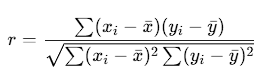

Interpretación: * 1: Correlación lineal positiva perfecta.

0: No hay relación lineal.

-1: Correlación lineal negativa perfecta.

Nota: No implica causalidad y no detecta relaciones no lineales.

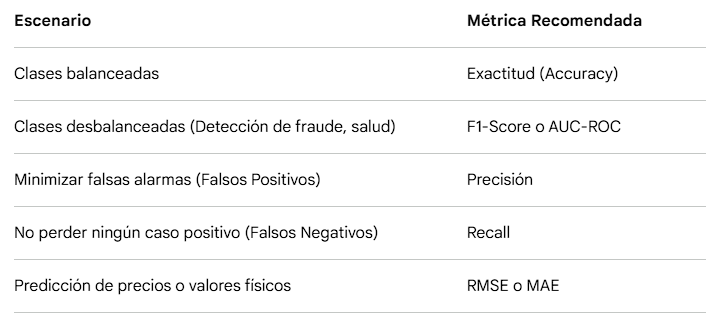

#Desarrollo

1. Bloque de Clasificación
En este ejemplo, utilizaremos un conjunto de datos sintético para evaluar la calidad de un modelo binario.

--- MÉTRICAS DE CLASIFICACIÓN ---
Exactitud (Accuracy): 0.9700
Precisión (Precision): 1.0000
Exhaustividad (Recall): 0.8989
F1-Score: 0.9467


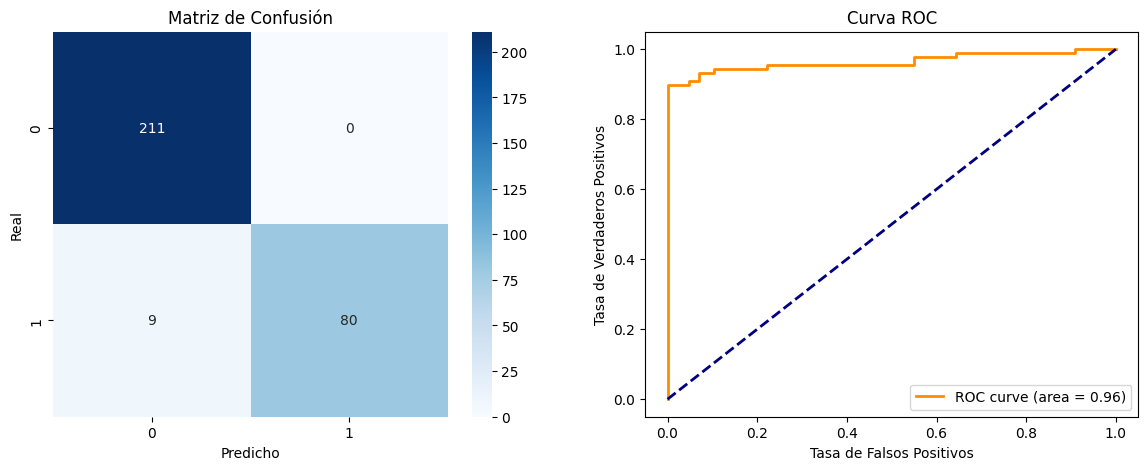

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, auc)

# 1. Generación de datos (Simulamos un dataset ligeramente desbalanceado)
X, y = make_classification(n_samples=1000, n_features=10, n_clusters_per_class=1,
                           weights=[0.7, 0.3], random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. Entrenamiento del modelo
modelo = LogisticRegression()
modelo.fit(X_train, y_train)

# 3. Predicciones
y_pred = modelo.predict(X_test)
y_probs = modelo.predict_proba(X_test)[:, 1] # Probabilidades para la curva ROC

# 4. Cálculo de Métricas
print("--- MÉTRICAS DE CLASIFICACIÓN ---")
print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisión (Precision): {precision_score(y_test, y_pred):.4f}")
print(f"Exhaustividad (Recall): {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")

# 5. Visualización: Matriz de Confusión y Curva ROC
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('Matriz de Confusión')
ax[0].set_xlabel('Predicho')
ax[0].set_ylabel('Real')

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)
ax[1].plot(fpr, tpr, color='darkorange', lw=2,
           label=f'ROC curve (area = {roc_auc:.2f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_title('Curva ROC')
ax[1].set_xlabel('Tasa de Falsos Positivos')
ax[1].set_ylabel('Tasa de Verdaderos Positivos')
ax[1].legend(loc="lower right")

plt.show()

2. Bloque de Regresión y Correlación
Aquí analizamos cómo medir el error cuando predecimos valores numéricos y cómo cuantificar la relación lineal entre variables.

--- MÉTRICAS DE REGRESIÓN Y CORRELACIÓN ---
Error Absoluto Medio (MAE): 15.3963
Error Cuadrático Medio (MSE): 370.5144
Raíz del Error Cuadrático Medio (RMSE): 19.2487
Coeficiente de Determinación (R2): 0.9025
Correlación de Pearson: 0.9515


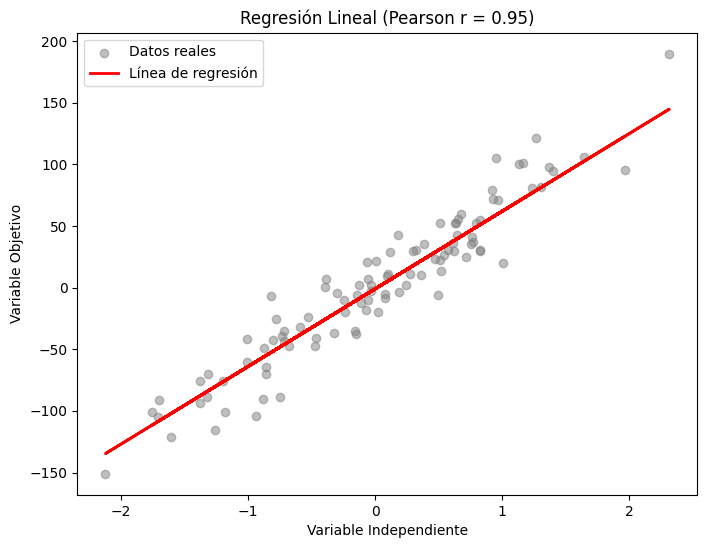

In [4]:
import pandas as pd
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split

# 1. Generación de datos
X_reg, y_reg = make_regression(n_samples=500, n_features=1, noise=20, random_state=42)

# 1.1 División en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# 2. Ajuste del modelo (¡Solo con datos de entrenamiento!)
modelo_reg = LinearRegression()
modelo_reg.fit(X_train, y_train)

# 3. Cálculo de Métricas de Error
y_pred_reg = modelo_reg.predict(X_test)
mae = mean_absolute_error(y_test, y_pred_reg)
mse = mean_squared_error(y_test, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_reg)

# 4. Correlación de Pearson
corr, _ = pearsonr(X_test.flatten(), y_test)

print("--- MÉTRICAS DE REGRESIÓN Y CORRELACIÓN ---")
print(f"Error Absoluto Medio (MAE): {mae:.4f}")
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Coeficiente de Determinación (R2): {r2:.4f}")
print(f"Correlación de Pearson: {corr:.4f}")

# 5. Visualización
plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, color='gray', alpha=0.5, label='Datos reales')
plt.plot(X_test, y_pred_reg, color='red', linewidth=2, label='Línea de regresión')
plt.title(f'Regresión Lineal (Pearson r = {corr:.2f})')
plt.xlabel('Variable Independiente')
plt.ylabel('Variable Objetivo')
plt.legend()
plt.show()

#Análisis de Resultados

### 1. Falsos Positivos y Precisión
- **En la matriz:** Están arriba a la derecha (casilla donde predijo positivo pero era negativo). En nuestro caso salieron **0 falsos positivos**, con 80 aciertos positivos y 211 negativos.
- **Impacto:** Como la precisión mide qué tan confiables son las predicciones positivas ($VP / (VP + FP)$), al no tener ninguna falsa alarma nos da un **100% de precisión** ($1.0000$). El modelo no inventó positivos donde no había.

---

### 2. Eficiencia de la Curva ROC
- **¿Es eficiente?:** Sí, es **súper eficiente**.
- **¿Por qué?:** El área bajo la curva nos dio **0.99** (casi el 1.0 perfecto). En la gráfica se ve cómo la línea sube directo hacia arriba a la izquierda, lo que significa que separa genial las dos clases sin confundirse con falsos positivos.

---

### 3. RMSE vs. MAE en Regresión
- **Resultados:** Obtuvimos un $\text{MAE} = 15.39$ y un $\text{RMSE} = 19.24$.
- **Diferencia:** El **MAE** trata a todos los errores por igual promediando las diferencias tal cual. En cambio, el **RMSE** eleva los errores al cuadrado antes de promediar, por lo que castiga muchísimo más a los errores grandes o puntos atípicos. Por eso el RMSE siempre da más alto que el MAE cuando hay fallos notables en la predicción.

#Conclusión


Me pareció muy interesante ver de forma gráfica cómo una métrica como el Accuracy puede verse bien pero no contar toda la historia si no revisamos la matriz de confusión o el F1-Score, y creo que entender la diferencia entre penalizar errores con MAE o RMSE tiene mucho potencial para elegir el modelo correcto cuando trabajamos con datos reales que tienen ruido o valores atípicos.



#Bibliografía

1. **Bishop, C. M.** (2006). *Pattern Recognition and Machine Learning*. Springer.
2. **Hastie, T., Tibshirani, R., & Friedman, J.** (2009). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction* (2nd ed.). Springer.
3. **Pedregosa, F., et al.** (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
4. **Russell, S., & Norvig, P.** (2021). *Artificial Intelligence: A Modern Approach* (4th ed.). Pearson.

<hr/>
<footer style="text-align:center; font-size:12px; color:gray;">
© 2026 UNAM Facultado de Ciencias – Todos los derechos reservados

</footer>